## Kelompok 5 - AI (B):
1. Rakharestna Razan P - 2206053215
2. Muhamad Jason T - 2206050415
3. Muhammad Izzudin Al Azzam - 2206810345
4. Saka Mayza Leksono - 2206824880
5. David Sitohang - 2206053114

##### Library dependensi yang diperlukan:
1. PyTorch
2. openpyxl 
3. matplotlib
4. pandas
5. scikit-learn
6. numpy
7. tqdm

Install dengan python-pip
``` bash
pip install pytorch tqdm matplotlib pandas seaborn scikit-learn numpy
```
Minimal Menjalankan Semua Cell Kira-kira 25 Menit

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import savgol_filter
import glob
import random
import os
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable

from tqdm.notebook import tqdm
from math import sqrt
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error


Using device: cuda


Kode ini menggunakan dataset CALCE dengan sub-dataset CS2_35 hingga CS2_38 dengan kondisi pengujian dilakukan pada suhu 1°C dengan metode pengisian menggunakan mode arus konstan (CC) hingga tegangan baterai mencapai 4,2V, kemudian dilanjutkan dengan mode tegangan konstan (CV) hingga arus pengisian turun menjadi 20mA. Proses pengosongan dilakukan dengan mode arus konstan (CC) hingga tegangan baterai turun ke 2,7V. Sebelum analisis data, beberapa outlier dalam data perlu dihilangkan.

In [2]:
def drop_outlier(array,count,bins):
    index = []
    range_ = np.arange(1,count,bins)
    for i in range_[:-1]:
        array_lim = array[i:i+bins]
        sigma = np.std(array_lim)
        mean = np.mean(array_lim)
        th_max,th_min = mean + sigma*2, mean - sigma*2
        idx = np.where((array_lim < th_max) & (array_lim > th_min))
        idx = idx[0] + i
        index.extend(list(idx))
    return np.array(index)

#### Tahap 1 : Load Data
###### Waktu agak lama sekitar 4-6 menit tergantung PC

In [3]:
Battery_list = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
dir_path = 'dataset/'
Battery = {}

for name in Battery_list:
    print('Load Dataset ' + name + ' ...')
    path = glob.glob(dir_path + name + '/*.xlsx')
    dates = []
    for p in path:
        df = pd.read_excel(p, sheet_name=1)
        print('Load ' + str(p) + ' ...')
        dates.append(df['Date_Time'][0])
    idx = np.argsort(dates)
    path_sorted = np.array(path)[idx]

    count = 0
    discharge_capacities = []
    health_indicator = []
    internal_resistance = []
    CCCT = []
    CVCT = []

    for p in path_sorted:
        df = pd.read_excel(p, sheet_name=1)
        print('Load ' + str(p) + ' ...')
        cycles = list(set(df['Cycle_Index']))
        for c in cycles:
            df_lim = df[df['Cycle_Index'] == c]
            # Charging
            df_c = df_lim[(df_lim['Step_Index'] == 2) | (df_lim['Step_Index'] == 4)]
            c_v = df_c['Voltage(V)']
            c_c = df_c['Current(A)']
            c_t = df_c['Test_Time(s)']
            # CC or CV
            df_cc = df_lim[df_lim['Step_Index'] == 2]
            df_cv = df_lim[df_lim['Step_Index'] == 4]
            CCCT.append(np.max(df_cc['Test_Time(s)']) - np.min(df_cc['Test_Time(s)']))
            CVCT.append(np.max(df_cv['Test_Time(s)']) - np.min(df_cv['Test_Time(s)']))

            # Discharging
            df_d = df_lim[df_lim['Step_Index'] == 7]
            d_v = df_d['Voltage(V)']
            d_c = df_d['Current(A)']
            d_t = df_d['Test_Time(s)']
            d_im = df_d['Internal_Resistance(Ohm)']

            if len(list(d_c)) != 0:
                time_diff = np.diff(list(d_t))
                d_c = np.array(list(d_c))[1:]
                discharge_capacity = time_diff * d_c / 3600  # Q = A*h
                discharge_capacity = [np.sum(discharge_capacity[:n]) for n in range(discharge_capacity.shape[0])]
                discharge_capacities.append(-1 * discharge_capacity[-1])

                dec = np.abs(np.array(d_v) - 3.8)[1:]
                start = np.array(discharge_capacity)[np.argmin(dec)]
                dec = np.abs(np.array(d_v) - 3.4)[1:]
                end = np.array(discharge_capacity)[np.argmin(dec)]
                health_indicator.append(-1 * (end - start))

                internal_resistance.append(np.mean(np.array(d_im)))
                count += 1

    # Convert lists to numpy arrays
    discharge_capacities = np.array(discharge_capacities)
    health_indicator = np.array(health_indicator)
    internal_resistance = np.array(internal_resistance)
    CCCT = np.array(CCCT)
    CVCT = np.array(CVCT)

    # Savitzky-Golay filter 
    window_length = 11  
    polyorder = 3

    if len(discharge_capacities) >= window_length:
        discharge_capacities = savgol_filter(discharge_capacities, window_length, polyorder)
        health_indicator = savgol_filter(health_indicator, window_length, polyorder)
        internal_resistance = savgol_filter(internal_resistance, window_length, polyorder)
        CCCT = savgol_filter(CCCT, window_length, polyorder)
        CVCT = savgol_filter(CVCT, window_length, polyorder)
    else:
        print(f'Data untuk {name} terlalu pendek untuk Savitzky-Golay filter.')

    idx = drop_outlier(discharge_capacities, count, 40)

    df_result = pd.DataFrame({
        'cycle': np.linspace(1, idx.shape[0], idx.shape[0]),
        'capacity': discharge_capacities[idx],
        'SoH': health_indicator[idx],
        'resistance': internal_resistance[idx],
        'CCCT': CCCT[idx],
        'CVCT': CVCT[idx]
    })

    Battery[name] = df_result

Load Dataset CS2_35 ...
Load dataset/CS2_35\CS2_35_10_15_10.xlsx ...
Load dataset/CS2_35\CS2_35_10_22_10.xlsx ...
Load dataset/CS2_35\CS2_35_10_29_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_01_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_08_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_23_10.xlsx ...
Load dataset/CS2_35\CS2_35_11_24_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_06_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_13_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_20_10.xlsx ...
Load dataset/CS2_35\CS2_35_12_23_10.xlsx ...
Load dataset/CS2_35\CS2_35_1_10_11.xlsx ...
Load dataset/CS2_35\CS2_35_1_18_11.xlsx ...
Load dataset/CS2_35\CS2_35_1_24_11.xlsx ...
Load dataset/CS2_35\CS2_35_1_28_11.xlsx ...
Load dataset/CS2_35\CS2_35_2_10_11.xlsx ...
Load dataset/CS2_35\CS2_35_2_4_11.xlsx ...
Load dataset/CS2_35\CS2_35_8_17_10.xlsx ...
Load dataset/CS2_35\CS2_35_8_18_10.xlsx ...
Load dataset/CS2_35\CS2_35_8_19_10.xlsx ...
Load dataset/CS2_35\CS2_35_8_30_10.xlsx ...
Load dataset/CS2_35\CS2_35_9_21_10.xlsx ..


 Battery: CS2_35

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 883 entries, 0 to 882
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       883 non-null    float64
 1   capacity    883 non-null    float64
 2   SoH         883 non-null    float64
 3   resistance  883 non-null    float64
 4   CCCT        883 non-null    float64
 5   CVCT        714 non-null    float64
dtypes: float64(6)
memory usage: 41.5 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  883.000000  883.000000  883.000000  883.000000   883.000000   
mean   442.000000    0.848431    0.612914    0.099586  4698.598468   
std    255.044441    0.212825    0.189874    0.009724  1480.503792   
min      1.000000    0.290775    0.096034    0.086021   855.520538   
25%    221.500000    0.735730    0.551570    0.092478  3872.621316   
50%    442.000000    0.947727    0.706034    

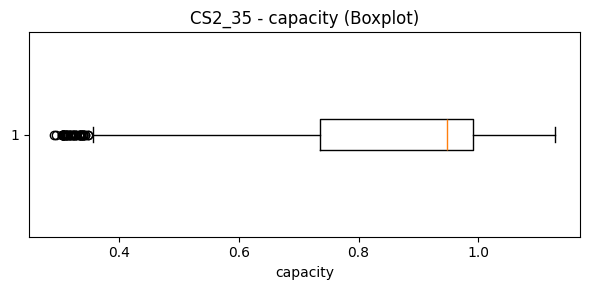

SoH: 91 outliers


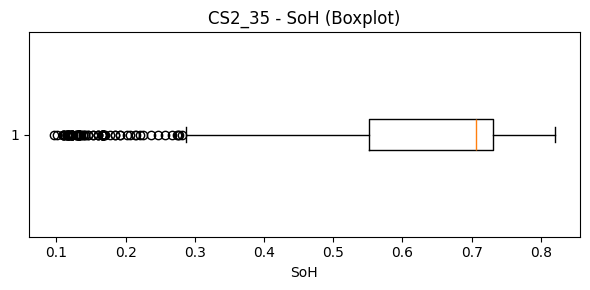

resistance: 42 outliers


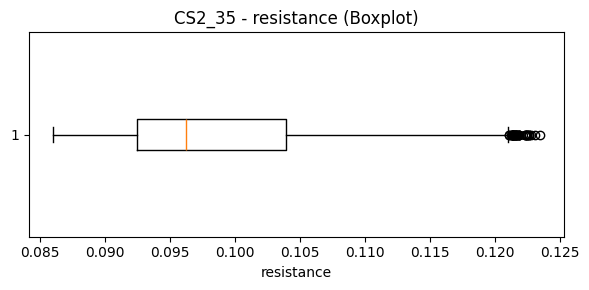

CCCT: 8 outliers


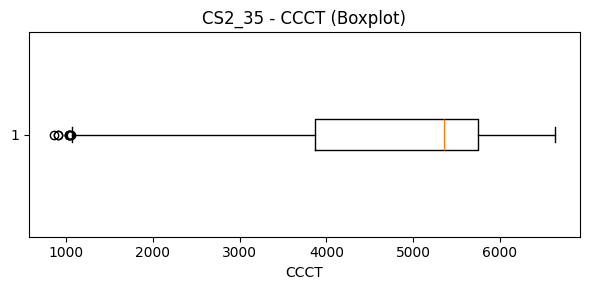

CVCT: 0 outliers


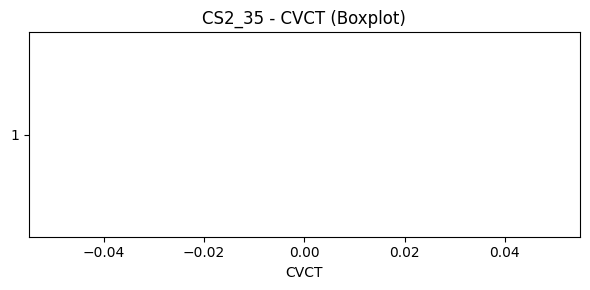


 Battery: CS2_36

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       919 non-null    float64
 1   capacity    919 non-null    float64
 2   SoH         919 non-null    float64
 3   resistance  919 non-null    float64
 4   CCCT        919 non-null    float64
 5   CVCT        756 non-null    float64
dtypes: float64(6)
memory usage: 43.2 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  919.000000  919.000000  919.000000  919.000000   919.000000   
mean   460.000000    0.817689    0.582348    0.096566  4531.772890   
std    265.436747    0.259070    0.219299    0.011226  1756.339888   
min      1.000000    0.156877    0.043285    0.083292   372.306159   
25%    230.500000    0.717140    0.525133    0.088207  3796.220347   
50%    460.000000    0.918245    0.670774    

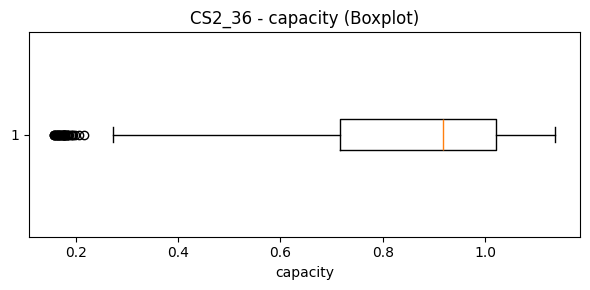

SoH: 116 outliers


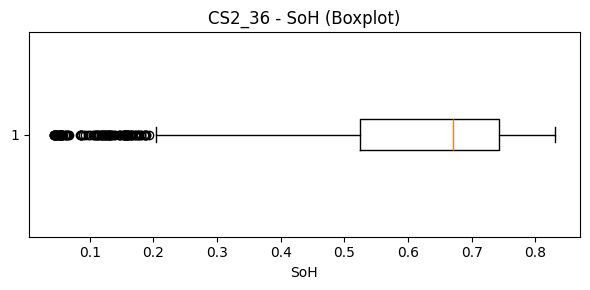

resistance: 75 outliers


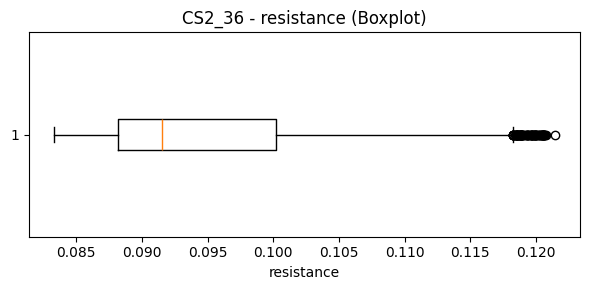

CCCT: 30 outliers


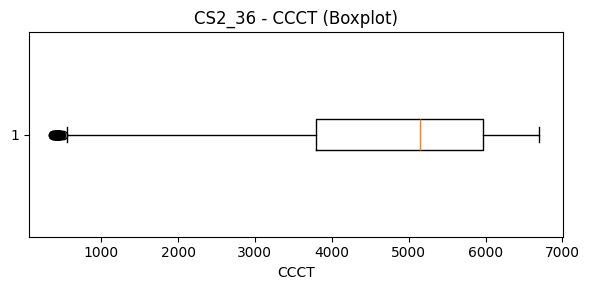

CVCT: 0 outliers


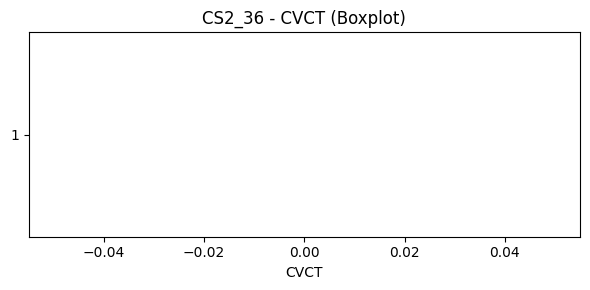


 Battery: CS2_37

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       947 non-null    float64
 1   capacity    947 non-null    float64
 2   SoH         947 non-null    float64
 3   resistance  947 non-null    float64
 4   CCCT        947 non-null    float64
 5   CVCT        809 non-null    float64
dtypes: float64(6)
memory usage: 44.5 KB
None

Descriptive Statistics :
            cycle    capacity         SoH  resistance         CCCT  \
count  947.000000  947.000000  947.000000  947.000000   947.000000   
mean   474.000000    0.841046    0.606137    0.097202  4656.959088   
std    273.519652    0.209647    0.183717    0.009477  1441.372872   
min      1.000000    0.199305    0.055377    0.085358   592.776992   
25%    237.500000    0.765158    0.568352    0.090242  4102.325334   
50%    474.000000    0.927346    0.684640    

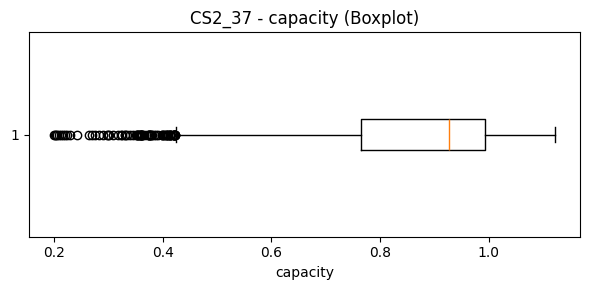

SoH: 110 outliers


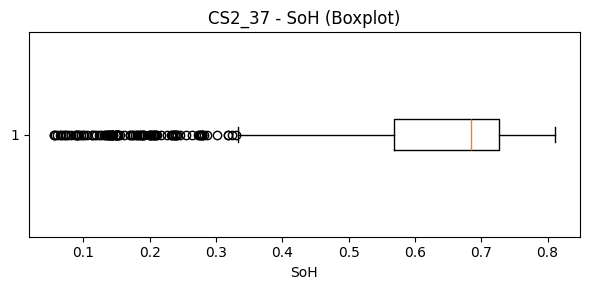

resistance: 92 outliers


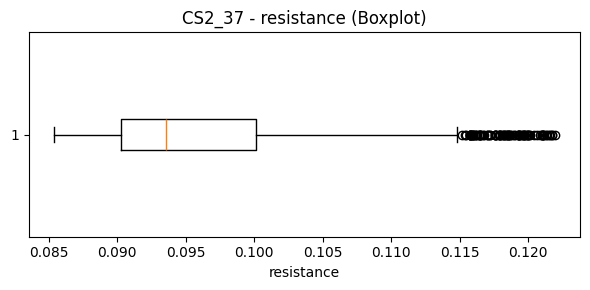

CCCT: 65 outliers


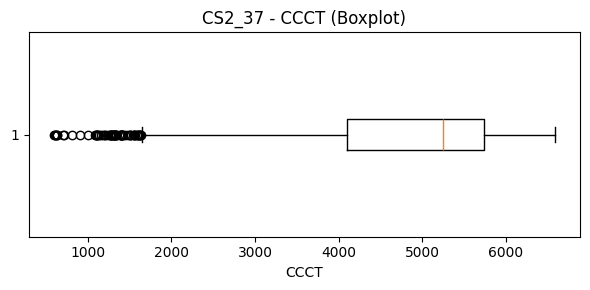

CVCT: 0 outliers


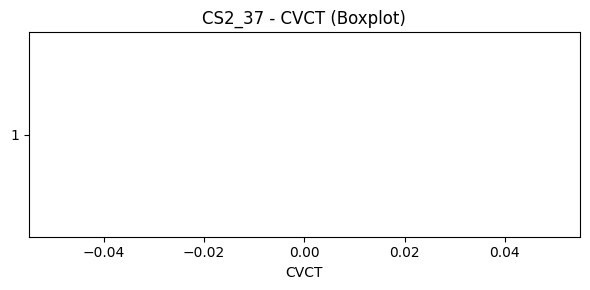


 Battery: CS2_38

Data Info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cycle       1001 non-null   float64
 1   capacity    1001 non-null   float64
 2   SoH         1001 non-null   float64
 3   resistance  1001 non-null   float64
 4   CCCT        1001 non-null   float64
 5   CVCT        879 non-null    float64
dtypes: float64(6)
memory usage: 47.1 KB
None

Descriptive Statistics :
             cycle     capacity          SoH   resistance         CCCT  \
count  1001.000000  1001.000000  1001.000000  1001.000000  1001.000000   
mean    501.000000     0.847574     0.618213     0.107076  4669.918531   
std     289.108111     0.205138     0.188294     0.019461  1424.235979   
min       1.000000     0.261077     0.073555     0.089889   874.026569   
25%     251.000000     0.770388     0.568073     0.095629  4132.161020   
50%     501.000000 

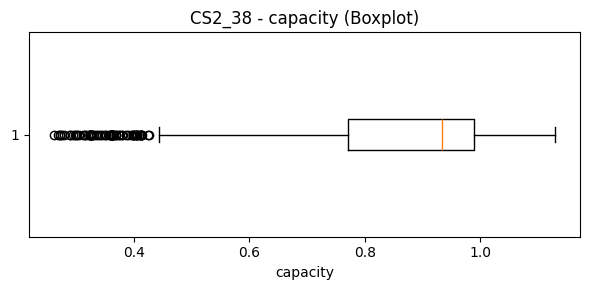

SoH: 114 outliers


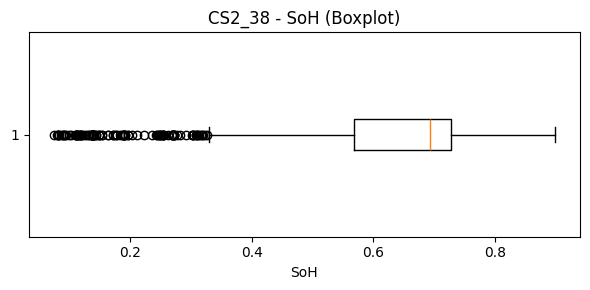

resistance: 87 outliers


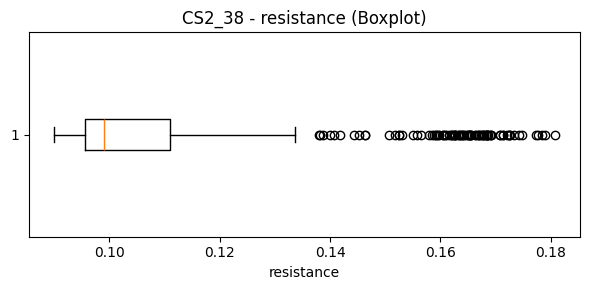

CCCT: 71 outliers


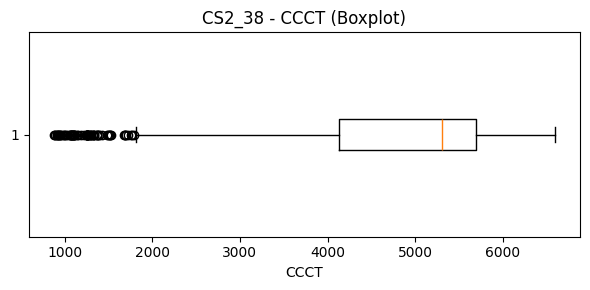

CVCT: 0 outliers


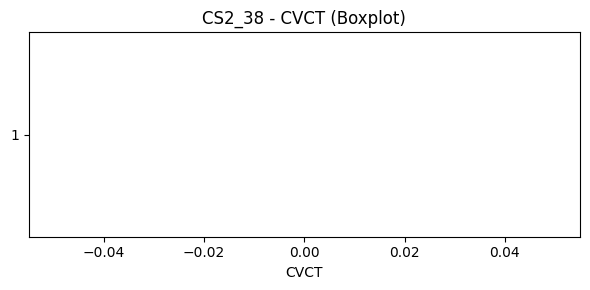

In [4]:
def check_outliers_and_info(Battery):
    for name, df in Battery.items():
        print(f"\n Battery: {name}")
        print("\nData Info :")
        print(df.info())

        print("\nDescriptive Statistics :")
        print(df.describe())

        print("\nOutlier Detection (IQR Method) :")
        for column in ['capacity', 'SoH', 'resistance', 'CCCT', 'CVCT']:
            Q1 = df[column].quantile(0.25)
            Q3 = df[column].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

            print(f"{column}: {len(outliers)} outliers")

            # Optional: Plot boxplot
            plt.figure(figsize=(6, 3))
            plt.boxplot(df[column], vert=False)
            plt.title(f'{name} - {column} (Boxplot)')
            plt.xlabel(column)
            plt.tight_layout()
            plt.show()
check_outliers_and_info(Battery)

#### Tahap 2 : Melihat Degradasi Kapasitas dari 4 Baterai

##### Dalam analisis baterai lithium, parameter utama yang diperhatikan adalah kapasitas, arus, dan tegangan, dengan fokus utama pada pemodelan kurva penurunan kapasitas selama siklus discharge untuk memprediksi umur baterai.


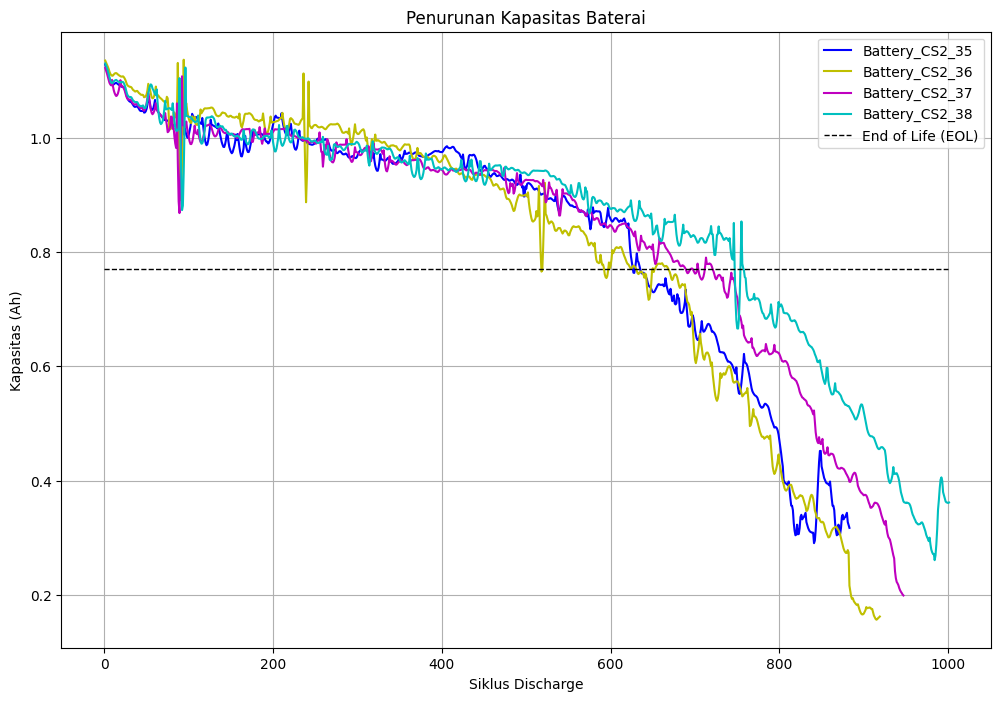

In [5]:
Rated_Capacity = 1.1 # Kapasitas terukur baterai menurun 30%, dari 1,1 Ahr menjadi 0,77 Ahr, sehingga 1,1 menjadi standar End Of Life (EOF)
fig, ax = plt.subplots(1, figsize=(12, 8))
color_list = ['b-', 'y-', 'm-', 'c-']
for name,color in zip(Battery_list, color_list):
    battery = Battery[name]
    ax.plot(battery['cycle'], battery['capacity'], color, label='Battery_'+name)
plt.plot([-1,1000],[Rated_Capacity*0.7, Rated_Capacity*0.7], c='black', lw=1, ls='--', label='End of Life (EOL)')  # 
ax.set(xlabel='Siklus Discharge', ylabel='Kapasitas (Ah)', title='Penurunan Kapasitas Baterai')
plt.legend()
plt.grid()
plt.savefig("./Gambar/Degradasi Kapasitas Baterai (Semua Baterai).png")
plt.show()

#### Tahap 3 : Menggunakan Gauss Fitting untuk Melihat Loss

In [6]:
def setup_seed(seed):
    np.random.seed(seed)  # Numpy module.
    random.seed(seed)  # Python random module.
    os.environ['PYTHONHASHSEED'] = str(seed) 
    torch.manual_seed(seed) # Set random seed for CPU
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed) # Set the random seed for the current GPU
        torch.cuda.manual_seed_all(seed) 
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

In [7]:
class Net_Gauss(nn.Module):
    def __init__(self, k=3, eps=1e-6):
        super(Net_Gauss, self).__init__()
        self.eps = eps
        self.w = torch.nn.Parameter(torch.randn((3, k)), requires_grad=True)
        
    def forward(self, x): 
        out = 0
        for i in range(k):
            out += self.w[0, i] * torch.exp(-torch.pow((x - self.w[1, i])/(self.w[2, i] + self.eps), 2)) 
        return out

In [8]:
def train_Gauss(data, k=3, lr=1e-4, stop=1e-3, epochs=100000, device=device):  
    model = Net_Gauss(k=k)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    loss_list = []
    epoch = 0
    while True:
        train_data = np.random.permutation(data)
        x, y = train_data[:,0], train_data[:,1]
        X, y = np.reshape(x, (-1, 1)).astype(np.float32), np.reshape(y, (-1, 1)).astype(np.float32)
        X, y = Variable(torch.from_numpy(X)).to(device), Variable(torch.from_numpy(y)).to(device)
        y_ = model(X)
        loss = criterion(y_, y)
        # print(loss.detach().numpy())
        optimizer.zero_grad()              
        loss.backward()                    # backpropagation
        optimizer.step()                   
        
        if epoch % 100 == 0:
            loss_list.append(loss.detach().cpu().numpy())
            
        if (loss.detach().cpu().numpy() < stop) or (epoch > epochs):
            break
            
        epoch +=1

    return model, loss_list

def predict(model, x, device=device):
    x = np.array(x).astype(np.float32)
    x = torch.from_numpy(x).to(device)
    model.eval()
    with torch.no_grad():
        y_ = model(x)
    return y_.detach().cpu().numpy()


Training on: CS2_35

Training on: CS2_36

Training on: CS2_37

Training on: CS2_38


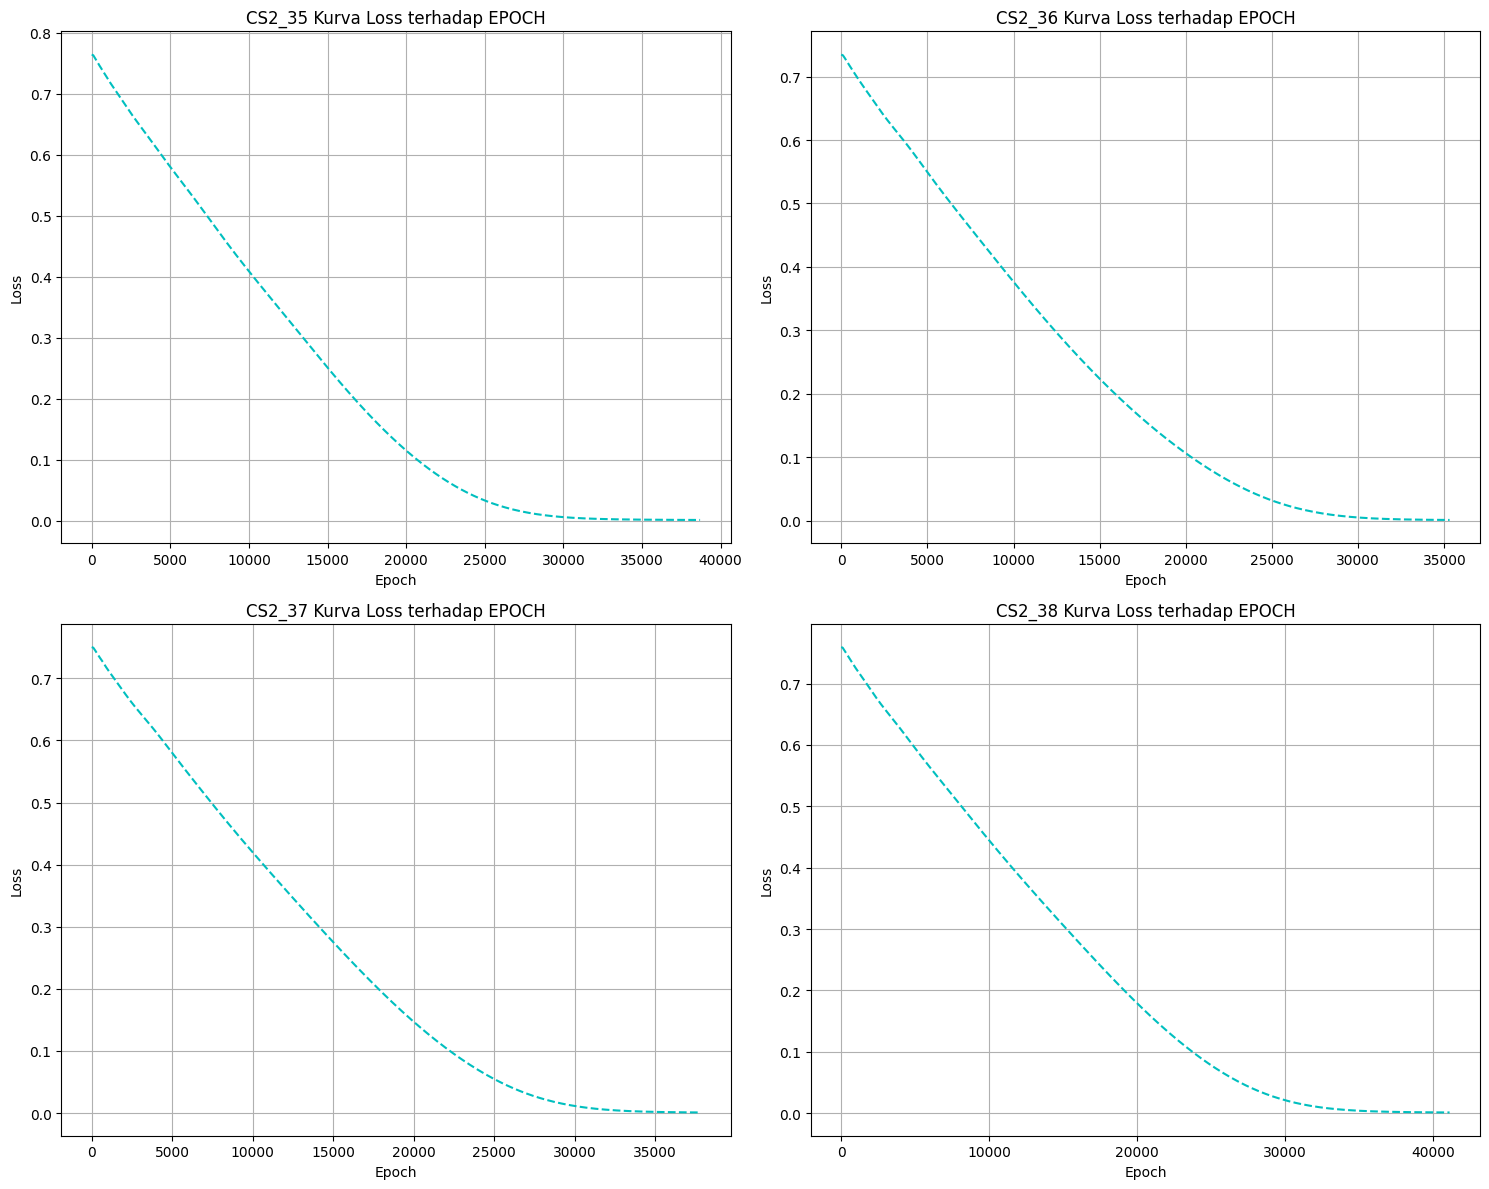

In [9]:
lr = 1e-2    # Learning Rate
k = 3
stop = 1e-3
epochs = 100000

fig, axs = plt.subplots(2, 2, figsize=(15, 12))  
axs = axs.flatten()

for i, name in enumerate(Battery_list):
    print(f'\nTraining on: {name}')
    setup_seed(seed=0)  

    df = Battery[name]
    x, y = np.array(df['cycle']), np.array(df['capacity'])

    model, loss_list = train_Gauss(data=np.c_[x, y], k=k, lr=lr, stop=stop, epochs=epochs, device=device)

    axs[i].plot(range(0, len(loss_list)*100, 100), loss_list, 'c--', label='Loss')
    axs[i].set_title(f'{name} Kurva Loss terhadap EPOCH')
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Loss')
    axs[i].grid(True)

plt.tight_layout()
plt.savefig("./Gambar/Kurva Loss terhadap EPOCH.png")
plt.show()

#### Tahap 4 : Menggunakan Multi-Layer Perceptron Neural Network (MLP) Model untuk Memodelkan SOH and RUL

In [10]:
def build_sequences(text, window_size):
    x, y = [], []
    for i in range(len(text) - window_size):
        sequence = text[i:i+window_size]
        target = text[i+1:i+1+window_size]
        x.append(sequence)
        y.append(target)
    return np.array(x), np.array(y)

def get_train_test(data_dict, name, window_size=8, train_ratio=0.):
    data_sequence = data_dict[name]['capacity']
    train_data, test_data = data_sequence[:window_size+1], data_sequence[window_size+1:]
    train_x, train_y = build_sequences(text=train_data, window_size=window_size)

    for k, v in data_dict.items():
        if k != name:
            data_x, data_y = build_sequences(text=v['capacity'], window_size=window_size)
            train_x = np.concatenate([train_x, data_x])
            train_y = np.concatenate([train_y, data_y])
            
    return train_x, train_y, list(train_data), list(test_data)

def evaluation(y_test, y_predict):
    r2 = r2_score(y_test, y_predict)
    mae = mean_absolute_error(y_test, y_predict)
    mse = mean_squared_error(y_test, y_predict)
    rmse = sqrt(mse)
    return mae, rmse, r2

def relative_error_MLP(y_test, y_predict, threshold):
    true_re, pred_re = len(y_test), 0
    for i in range(len(y_test)-1):
        if y_test[i] <= threshold >= y_test[i+1]:
            true_re = i - 1
            break
    for i in range(len(y_predict)-1):
        if y_predict[i] <= threshold:
            pred_re = i - 1
            break
    return abs(true_re - pred_re) / true_re

In [11]:
class Net_MLP(nn.Module):
    def __init__(self, feature_size=8, hidden_size=[16, 8]):
        super(Net_MLP, self).__init__()
        self.layer0 = nn.Linear(feature_size, hidden_size[0])
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(hidden_size[i], hidden_size[i+1]), nn.ReLU())
            for i in range(len(hidden_size) - 1)
        ])
        self.linear = nn.Linear(hidden_size[-1], 1)

    def forward(self, x):
        out = self.layer0(x)
        for layer in self.layers:
            out = layer(out)
        return self.linear(out)


In [12]:
def train_MLP(LR_MLP=0.01, feature_size_MLP=8, hidden_size_MLP=[16, 8], weight_decay_MLP=0.0, window_size_MLP=8, EPOCH_MLP=1000, seed=0):
    mae_list, rmse_list, re_list, rsquare_list = [], [], [], []
    result_list = []

    for i in range(4):
        name = Battery_list[i]
        train_x, train_y, train_data, test_data = get_train_test(Battery, name, window_size_MLP)

        print(f"[{name}] train_x: {train_x.shape}, train_y: {train_y.shape}")
        setup_seed(seed)
        model = Net_MLP(feature_size=feature_size_MLP, hidden_size=hidden_size_MLP).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=LR_MLP, weight_decay=weight_decay_MLP)
        criterion = nn.MSELoss()

        test_x = train_data.copy()
        loss_list, y_ = [0], []

        for epoch in range(EPOCH_MLP):
            X = torch.from_numpy(train_x.astype(np.float32) / Rated_Capacity).to(device)
            y = torch.from_numpy(train_y[:, -1].astype(np.float32) / Rated_Capacity).view(-1, 1).to(device)

            if X.shape[1] != feature_size_MLP:
                raise ValueError(f"Expected input feature size {feature_size_MLP}, but got {X.shape[1]}")

            output = model(X)
            loss = criterion(output, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if (epoch + 1) % 100 == 0:
                test_x = train_data.copy()
                point_list = []

                while len(test_x) - len(train_data) < len(test_data):
                    x_input = np.array(test_x[-feature_size_MLP:]).astype(np.float32) / Rated_Capacity
                    x = torch.from_numpy(x_input.reshape(1, -1)).to(device)
                    pred = model(x)
                    next_point = pred.detach().cpu().numpy()[0, 0] * Rated_Capacity
                    test_x.append(next_point)
                    point_list.append(next_point)

                y_.append(point_list)
                loss_list.append(loss.item())
                mae, rmse, rsquare = evaluation(y_test=test_data, y_predict=y_[-1])
                re = relative_error_MLP(y_test=test_data, y_predict=y_[-1], threshold=Rated_Capacity * 0.7)
                print(f'epoch:{epoch:<4d} | loss:{loss.item():<8.6f} | R2:{rsquare:<6.4f} | MAE:{mae:<6.4f} | RMSE:{rmse:<6.4f} | RE:{re:<6.4f}')

            if len(loss_list) > 1 and abs(loss_list[-2] - loss_list[-1]) < 1e-6:
                break

        mae, rmse, rsquare = evaluation(test_data, y_[-1])
        re = relative_error_MLP(test_data, y_[-1], threshold=Rated_Capacity * 0.7)
        mae_list.append(mae)
        rsquare_list.append(rsquare)
        rmse_list.append(rmse)
        re_list.append(re)
        result_list.append(y_[-1])

    return re_list, mae_list, rmse_list, rsquare_list, result_list


In [13]:
# Loop Training with Different Seeds
window_size = 8
Epoch = 1000
LR1 = 0.01
feature_size = window_size
hidden_size = [32, 16]
weight_decay = 0.0
Rated_Capacity = 1.1 # Kapasitas terukur baterai menurun 30%, dari 1,1 Ahr menjadi 0,77 Ahr, sehingga 1,1 menjadi standar End Of Life (EOF)

MAE, RMSE, RE, R2 = [], [], [], []

for seed in range(10):
    re_list, mae_list, rmse_list, rsquare_list, _ = train_MLP(
        LR_MLP=LR1,
        feature_size_MLP=feature_size,
        hidden_size_MLP=hidden_size,
        weight_decay_MLP=weight_decay,
        window_size_MLP=window_size,
        EPOCH_MLP=Epoch,
        seed=seed
    )
    R2.append(np.mean(np.array(rsquare_list)))
    RE.append(np.mean(np.array(re_list)))
    MAE.append(np.mean(np.array(mae_list)))
    RMSE.append(np.mean(np.array(rmse_list)))
    print('------------------------------------------------------------------')

print('R2:   mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(R2), np.std(R2)))
print('RE:   mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(RE), np.std(RE)))
print('MAE:  mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(MAE), np.std(MAE)))
print('RMSE: mean: {:<6.4f} | std: {:<6.4f}'.format(np.mean(RMSE), np.std(RMSE)))


[CS2_35] train_x: (2844, 8), train_y: (2844, 8)
epoch:99   | loss:0.000312 | R2:0.3070 | MAE:0.1378 | RMSE:0.1766 | RE:0.3393
epoch:199  | loss:0.000296 | R2:0.9468 | MAE:0.0382 | RMSE:0.0489 | RE:0.0016
epoch:299  | loss:0.000280 | R2:0.9395 | MAE:0.0398 | RMSE:0.0522 | RE:0.0146
epoch:399  | loss:0.000263 | R2:0.9322 | MAE:0.0418 | RMSE:0.0552 | RE:0.0260
epoch:499  | loss:0.000244 | R2:0.9226 | MAE:0.0442 | RMSE:0.0590 | RE:0.0390
epoch:599  | loss:0.000226 | R2:0.9121 | MAE:0.0465 | RMSE:0.0629 | RE:0.0503
epoch:699  | loss:0.000208 | R2:0.9030 | MAE:0.0487 | RMSE:0.0661 | RE:0.0584
epoch:799  | loss:0.000190 | R2:0.8984 | MAE:0.0498 | RMSE:0.0676 | RE:0.0633
epoch:899  | loss:0.000174 | R2:0.9005 | MAE:0.0492 | RMSE:0.0669 | RE:0.0601
epoch:999  | loss:0.000159 | R2:0.9098 | MAE:0.0470 | RMSE:0.0637 | RE:0.0519
[CS2_36] train_x: (2808, 8), train_y: (2808, 8)
epoch:99   | loss:0.000281 | R2:0.7471 | MAE:0.0812 | RMSE:0.1300 | RE:0.1874
epoch:199  | loss:0.000258 | R2:0.9360 | MAE:0

[CS2_35] train_x: (2844, 8), train_y: (2844, 8)
epoch:99   | loss:0.000246 | R2:0.1043 | MAE:0.1305 | RMSE:0.2008 | RE:1.0000
epoch:199  | loss:0.000228 | R2:0.9420 | MAE:0.0396 | RMSE:0.0511 | RE:0.0032
epoch:299  | loss:0.000221 | R2:0.9297 | MAE:0.0426 | RMSE:0.0563 | RE:0.0244
epoch:399  | loss:0.000214 | R2:0.9258 | MAE:0.0435 | RMSE:0.0578 | RE:0.0292
epoch:499  | loss:0.000206 | R2:0.9213 | MAE:0.0446 | RMSE:0.0595 | RE:0.0357
epoch:599  | loss:0.000198 | R2:0.9167 | MAE:0.0456 | RMSE:0.0612 | RE:0.0406
epoch:699  | loss:0.000189 | R2:0.9103 | MAE:0.0470 | RMSE:0.0635 | RE:0.0471
epoch:799  | loss:0.000180 | R2:0.9045 | MAE:0.0483 | RMSE:0.0655 | RE:0.0536
epoch:899  | loss:0.000171 | R2:0.9000 | MAE:0.0493 | RMSE:0.0671 | RE:0.0584
epoch:999  | loss:0.000162 | R2:0.8966 | MAE:0.0501 | RMSE:0.0682 | RE:0.0601
[CS2_36] train_x: (2808, 8), train_y: (2808, 8)
epoch:99   | loss:0.000270 | R2:0.2626 | MAE:0.1624 | RMSE:0.2219 | RE:1.0000
epoch:199  | loss:0.000200 | R2:0.6983 | MAE:0

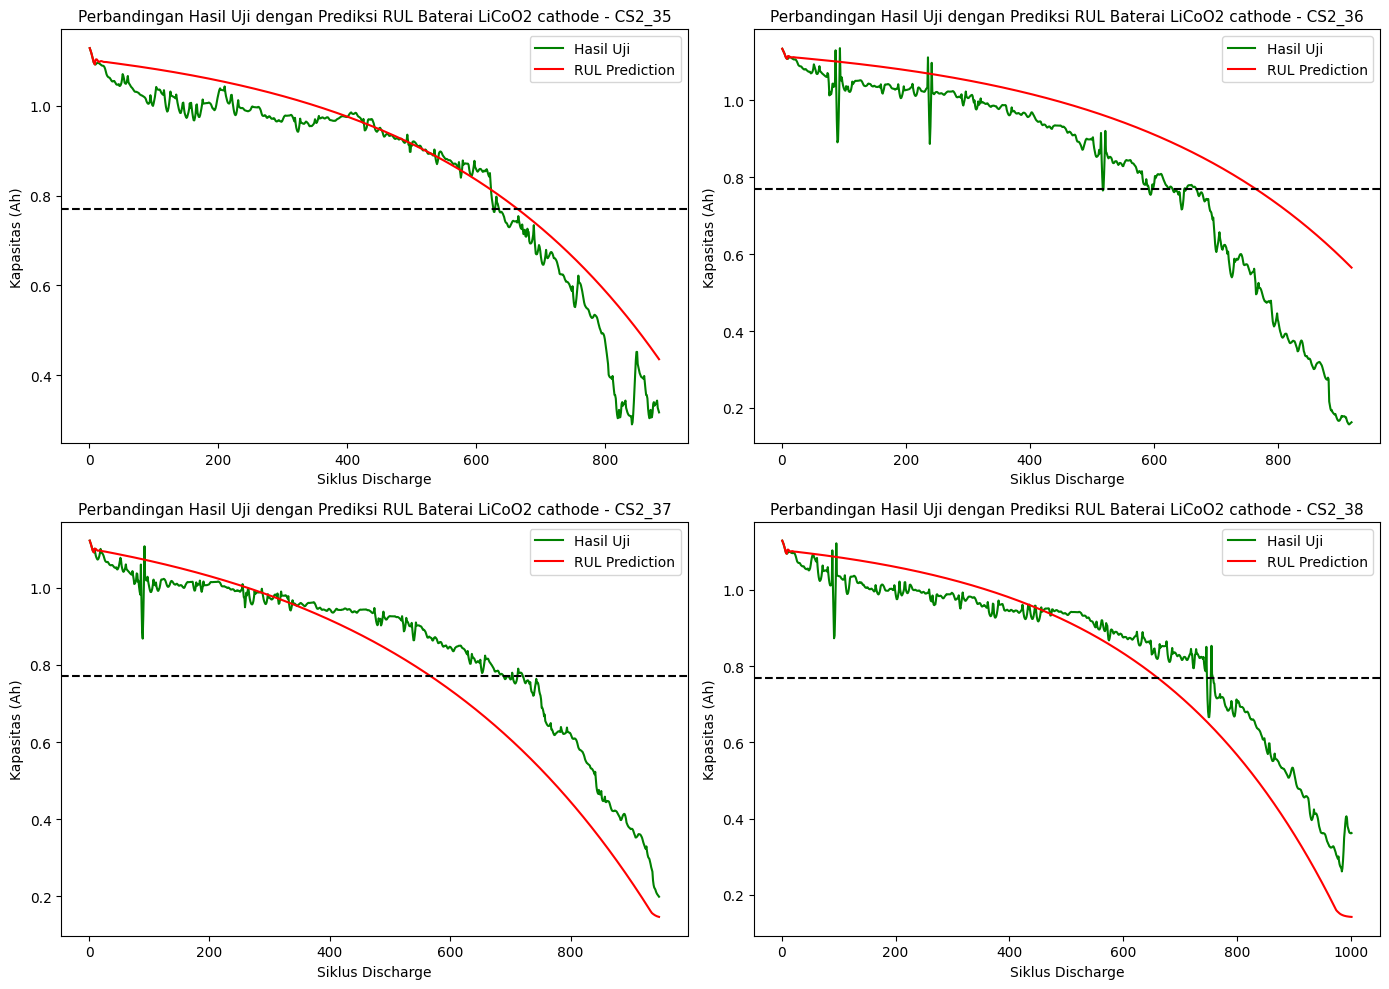

In [14]:
seed = 6
_, _, _, _, result_list = train_MLP(
    LR_MLP=LR1,
    feature_size_MLP=feature_size,
    hidden_size_MLP=hidden_size,
    weight_decay_MLP=weight_decay,
    window_size_MLP=window_size,
    EPOCH_MLP=Epoch,
    seed=seed
)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()

for i in range(4):
    name = Battery_list[i]
    train_x, train_y, train_data, test_data = get_train_test(Battery, name, window_size)

    prediction = train_data[:window_size+1].copy()
    prediction.extend(result_list[i])

    battery = Battery[name]
    axs[i].plot(battery['cycle'], battery['capacity'], 'g-', label='Hasil Uji')
    axs[i].plot(battery['cycle'], prediction, 'r-', label='RUL Prediction')
    axs[i].axhline(y=Rated_Capacity * 0.7, color='black', linestyle='--')
    axs[i].set_title('Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode - ' + name, fontsize=11)
    axs[i].set_xlabel('Siklus Discharge')
    axs[i].set_ylabel('Kapasitas (Ah)')
    axs[i].legend()

plt.tight_layout()
plt.savefig("./Gambar/SOH & RUL (MLP).png")
plt.show()


#### Tahap 5 : Memakai Recurrent Neural Networks (RNN), Long Short-Term Memory (LSTM), dan Gated Recurrent Unit (GRU) untuk Memodelkan SOH and RUL 


In [15]:
# Data Preparation & Evaluation
def build_instances(sequence, window_size):
    x, y = [], []
    for i in range(len(sequence) - window_size):
        features = sequence[i:i+window_size]
        target = sequence[i+window_size]
        x.append(features)
        y.append(target)
    return np.array(x).astype(np.float32), np.array(y).astype(np.float32)

def get_train_test(data_dict, name, window_size=8):
    data_sequence = data_dict[name]['capacity']
    train_data, test_data = data_sequence[:window_size+1], data_sequence[window_size+1:]
    train_x, train_y = build_instances(train_data, window_size)
    for k, v in data_dict.items():
        if k != name:
            data_x, data_y = build_instances(v['capacity'], window_size)
            train_x, train_y = np.r_[train_x, data_x], np.r_[train_y, data_y]
    return train_x, train_y, list(train_data), list(test_data)

def relative_error(y_test, y_predict, threshold):
    true_re, pred_re = len(y_test), 0
    for i in range(len(y_test)-1):
        if y_test[i] <= threshold >= y_test[i+1]:
            true_re = i - 1
            break
    for i in range(len(y_predict)-1):
        if y_predict[i] <= threshold:
            pred_re = i - 1
            break
    return abs(true_re - pred_re)/true_re if abs(true_re - pred_re)/true_re <= 1 else 1

def evaluation(y_test, y_predict):
    r2 = r2_score(y_test, y_predict)
    rmse = sqrt(mean_squared_error(y_test, y_predict))
    mae = mean_absolute_error(y_test, y_predict)
    return mae, rmse, r2

In [16]:
class Net_RNN_LSTM_GRU(nn.Module):
    def __init__(self, hidden_dim=8, num_layers=1, mode='RNN'): # RNN or LSTM or GRU
        super(Net_RNN_LSTM_GRU, self).__init__()
        self.hidden_dim = hidden_dim
        if mode == 'LSTM':
            self.cell = nn.LSTM(input_size=1, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
        elif mode == 'RNN':
            self.cell = nn.RNN(input_size=1, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
        elif mode == 'GRU':
            self.cell = nn.GRU(input_size=1, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
        else:
            raise ValueError("Mode must be either 'LSTM', 'RNN', or 'GRU'")
        self.linear = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out, _ = self.cell(x)
        out = out[:, -1, :]
        out = self.linear(out)
        return out

In [17]:
# Training Loop
def train_model(lr, feature_size, hidden_dim=64, num_layers=2, weight_decay=0.0, mode='RNN', # RNN or LSTM
                epochs=100, seed=0, device='cpu', metric='rmse'):
    score_list, result_list = [], []
    setup_seed(seed)

    for i in range(4):
        name = Battery_list[i]
        train_x, train_y, train_data, test_data = get_train_test(Battery, name, feature_size)
        test_sequence = train_data + test_data
        test_x, test_y = build_instances(test_sequence, feature_size)

        model = Net_RNN_LSTM_GRU(hidden_dim=hidden_dim, num_layers=num_layers, mode=mode).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        criterion = nn.MSELoss()

        y_ = []
        best_score = 1

        for epoch in range(epochs):
            X = np.reshape(train_x / Rated_Capacity, (-1, feature_size, 1))
            y = np.reshape(train_y / Rated_Capacity, (-1, 1))
            X, y = torch.from_numpy(X).to(device), torch.from_numpy(y).to(device)

            output = model(X).reshape(-1, 1)
            loss = criterion(output, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if (epoch + 1) % 10 == 0:
                x = np.reshape(test_x / Rated_Capacity, (-1, feature_size, 1))
                x = torch.from_numpy(x).to(device)
                pred = model(x).data.cpu().numpy().reshape(-1) * Rated_Capacity
                y_.append(pred)

                mae, rmse, r2 = evaluation(test_y, y_[-1])
                re = relative_error(test_y, y_[-1], Rated_Capacity * 0.7)

                score = [re, mae, rmse, r2]
                if loss < 1e-3 and best_score < score[2]:
                    break
                best_score = score[2]

        score_list.append(score)
        result_list.append(train_data.copy()[:-1] + list(y_[-1]))

    return score_list, result_list


In [18]:
# Multiple Seeds Evaluation - Untuk Final
# Single Seed digunakan untuk trial test.
feature_size = 64
EPOCH = 100
lr = 0.001 # Learning Rate
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
mode = 'RNN'
Rated_Capacity = 1.1 # Kapasitas terukur baterai menurun 30%, dari 1,1 Ahr menjadi 0,77 Ahr, sehingga 1,1 menjadi standar End Of Life (EOF)
metric = 'rmse'
device = 'cpu'

SCORE = []
for seed in tqdm(range(4)):
    print('seed: ', seed)
    score_list, _ = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim, num_layers=num_layers, 
                         weight_decay=weight_decay, mode=mode, epochs=EPOCH, seed=seed, device=device, metric='rmse')
    
    print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
    print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
    print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
    print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")
    for s in score_list:
        SCORE.append(s)
    print('------------------------------------------------------------------')

  0%|          | 0/4 [00:00<?, ?it/s]

seed:  0
[BT1]      RE : 0.083779 ,  MAE : 0.056321 ,  RMSE : 0.070892 ,  R2 : 0.887175
[BT2]      RE : 0.278761 ,  MAE : 0.019988 ,  RMSE : 0.026021 ,  R2 : 0.989732
[BT3]      RE : 0.073836 ,  MAE : 0.017036 ,  RMSE : 0.022193 ,  R2 : 0.988540
[BT4]      RE : 0.005865 ,  MAE : 0.026665 ,  RMSE : 0.047696 ,  R2 : 0.944365
------------------------------------------------------------------
seed:  1
[BT1]      RE : 0.021390 ,  MAE : 0.009598 ,  RMSE : 0.015731 ,  R2 : 0.994444
[BT2]      RE : 0.174779 ,  MAE : 0.025741 ,  RMSE : 0.042530 ,  R2 : 0.972569
[BT3]      RE : 0.008026 ,  MAE : 0.017591 ,  RMSE : 0.028384 ,  R2 : 0.981255
[BT4]      RE : 0.004399 ,  MAE : 0.011239 ,  RMSE : 0.020114 ,  R2 : 0.990106
------------------------------------------------------------------
seed:  2
[BT1]      RE : 0.028520 ,  MAE : 0.011331 ,  RMSE : 0.017857 ,  R2 : 0.992842
[BT2]      RE : 0.272124 ,  MAE : 0.012652 ,  RMSE : 0.020281 ,  R2 : 0.993762
[BT3]      RE : 0.075441 ,  MAE : 0.017671 ,  RMS

In [19]:
# Single Training Run: RNN
seed = 2
feature_size = 64
epochs = 100
lr = 0.001
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
Rated_Capacity = 1.1
mode = 'RNN'
metric = 'rmse'
device = 'cpu'

print('seed:', seed)
score_list, prediction_list = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim,
                                          num_layers=num_layers, weight_decay=weight_decay,
                                          mode=mode, epochs=epochs, seed=seed, device=device,
                                          metric=metric)

print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")


seed: 2
[BT1]      RE : 0.028520 ,  MAE : 0.011331 ,  RMSE : 0.017857 ,  R2 : 0.992842
[BT2]      RE : 0.272124 ,  MAE : 0.012652 ,  RMSE : 0.020281 ,  R2 : 0.993762
[BT3]      RE : 0.075441 ,  MAE : 0.017671 ,  RMSE : 0.022303 ,  R2 : 0.988426
[BT4]      RE : 0.004399 ,  MAE : 0.012257 ,  RMSE : 0.019407 ,  R2 : 0.990789


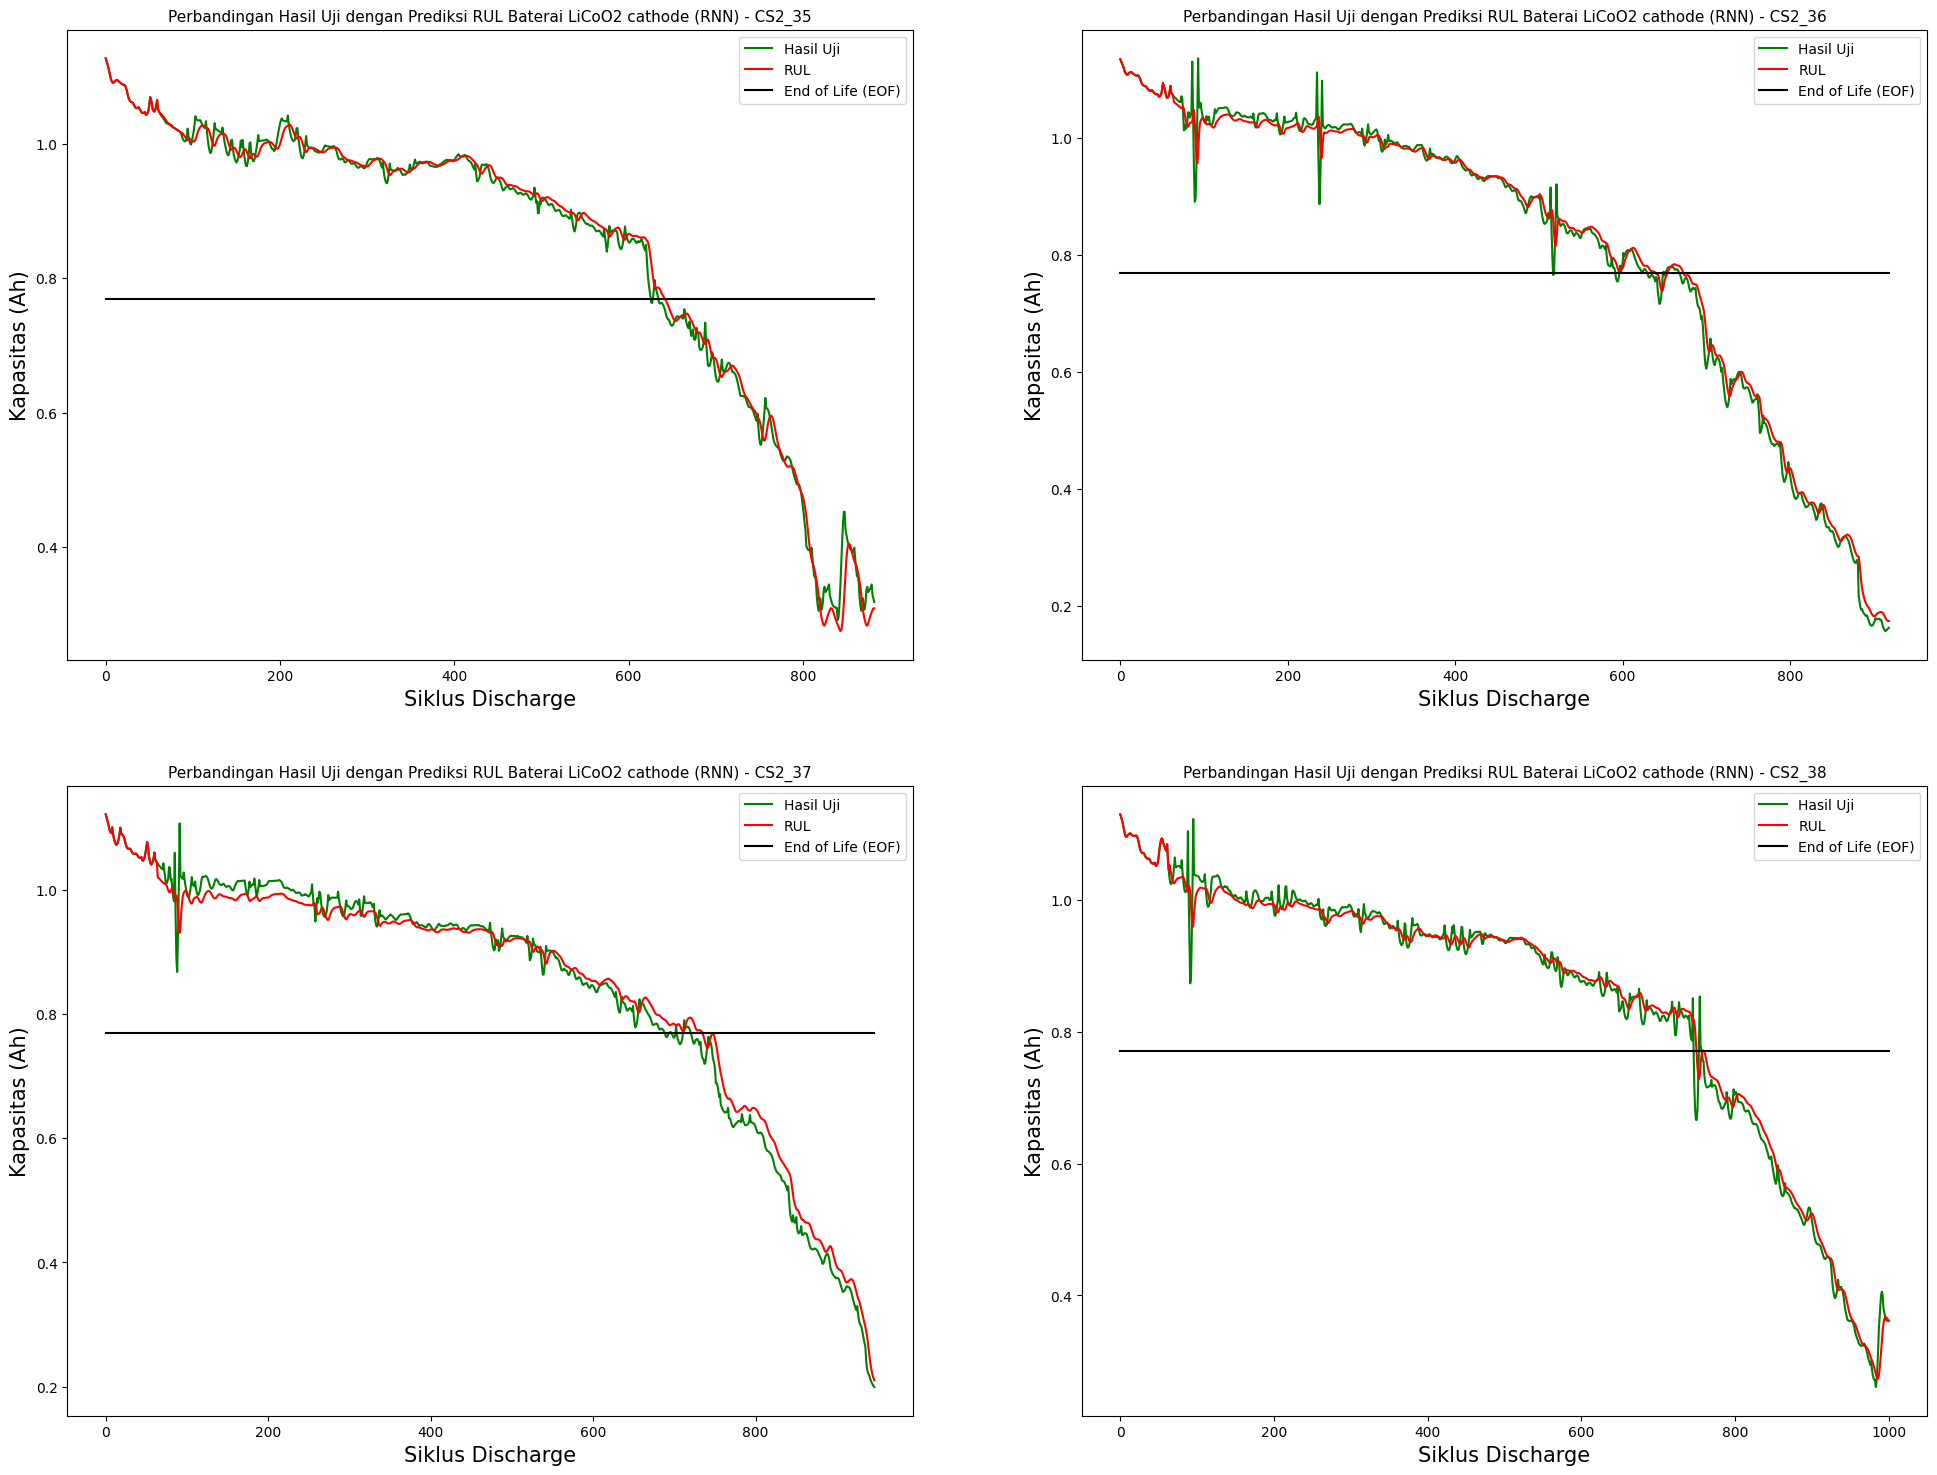

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(24, 18))

for i in range(2):
    for j in range(2):
        t = 2 * i + j
        battery_name = Battery_list[t]
        test_data = Battery[battery_name]['capacity']
        predict_data = prediction_list[t]
        score_data = score_list[t]
        x = list(range(len(test_data)))
        threshold = [Rated_Capacity * 0.7] * len(test_data)

        ax[i][j].plot(x, test_data, 'g', label='Hasil Uji')
        ax[i][j].plot(x, predict_data, 'r', label='RUL')
        ax[i][j].plot(x, threshold, 'black', ls='-', label='End of Life (EOF)')
        ax[i][j].legend()
        ax[i][j].set_xlabel('Siklus Discharge', fontsize=15)
        ax[i][j].set_ylabel('Kapasitas (Ah)', fontsize=15)
        ax[i][j].set_title(f'Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode (RNN) - {battery_name}', fontsize=11)

plt.savefig("./Gambar/SOH & RUL (RNN).png")
plt.show()

seed: 2
[BT1]      RE : 0.137255 ,  MAE : 0.084708 ,  RMSE : 0.114425 ,  R2 : 0.706061
[BT2]      RE : 0.402655 ,  MAE : 0.104185 ,  RMSE : 0.137698 ,  R2 : 0.712449
[BT3]      RE : 0.104334 ,  MAE : 0.074727 ,  RMSE : 0.096816 ,  R2 : 0.781905
[BT4]      RE : 0.035191 ,  MAE : 0.057120 ,  RMSE : 0.079682 ,  R2 : 0.844724


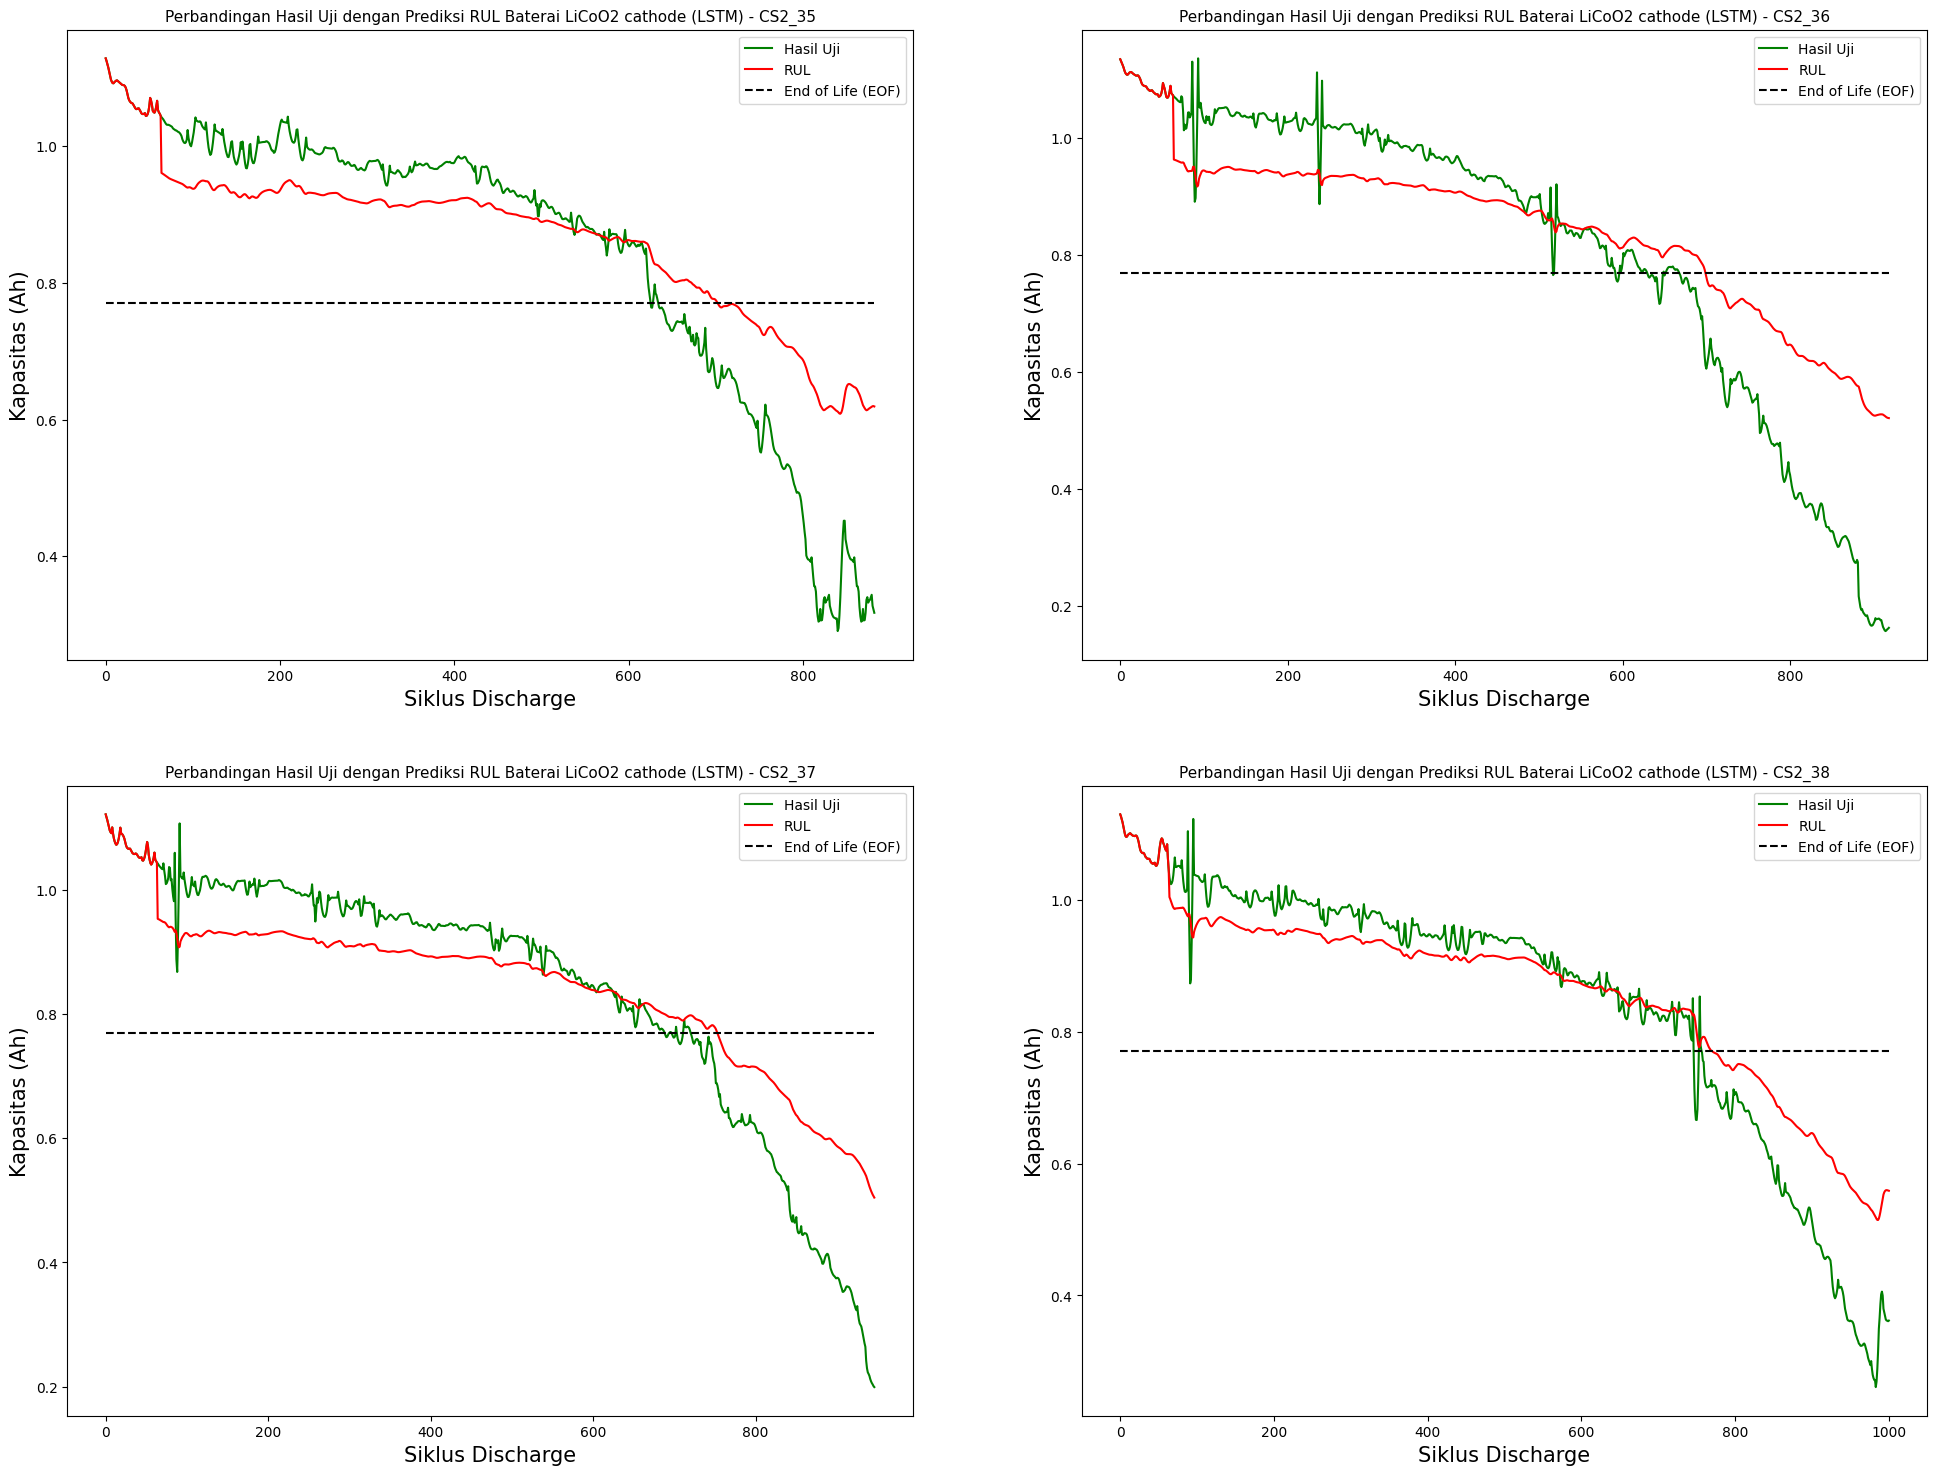

In [21]:
# Single Training Run: LSTM
seed = 2
feature_size = 64
epochs = 100
lr = 0.001
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
Rated_Capacity = 1.1
mode = 'LSTM'
metric = 'rmse'
device = 'cpu'

print('seed:', seed)
score_list, prediction_list = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim,
                                          num_layers=num_layers, weight_decay=weight_decay,
                                          mode=mode, epochs=epochs, seed=seed, device=device,
                                          metric=metric)

print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")

fig, ax = plt.subplots(2, 2, figsize=(24, 18))

for i in range(2):
    for j in range(2):
        t = 2 * i + j
        battery_name = Battery_list[t]
        test_data = Battery[battery_name]['capacity']
        predict_data = prediction_list[t]
        score_data = score_list[t]
        x = list(range(len(test_data)))
        threshold = [Rated_Capacity * 0.7] * len(test_data)

        ax[i][j].plot(x, test_data, 'g', label='Hasil Uji')
        ax[i][j].plot(x, predict_data, 'r', label='RUL')
        ax[i][j].plot(x, threshold, 'black', ls='--', label='End of Life (EOF)')
        ax[i][j].legend()
        ax[i][j].set_xlabel('Siklus Discharge', fontsize=15)
        ax[i][j].set_ylabel('Kapasitas (Ah)', fontsize=15)
        ax[i][j].set_title(f'Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode (LSTM) - {battery_name}', fontsize=11)

plt.savefig("./Gambar/SOH & RUL (LSTM).png")
plt.show()


seed: 2
[BT1]      RE : 0.083779 ,  MAE : 0.065013 ,  RMSE : 0.081283 ,  R2 : 0.851676
[BT2]      RE : 0.404867 ,  MAE : 0.122090 ,  RMSE : 0.158123 ,  R2 : 0.620817
[BT3]      RE : 0.105939 ,  MAE : 0.079077 ,  RMSE : 0.102232 ,  R2 : 0.756821
[BT4]      RE : 0.005865 ,  MAE : 0.062353 ,  RMSE : 0.080906 ,  R2 : 0.839917


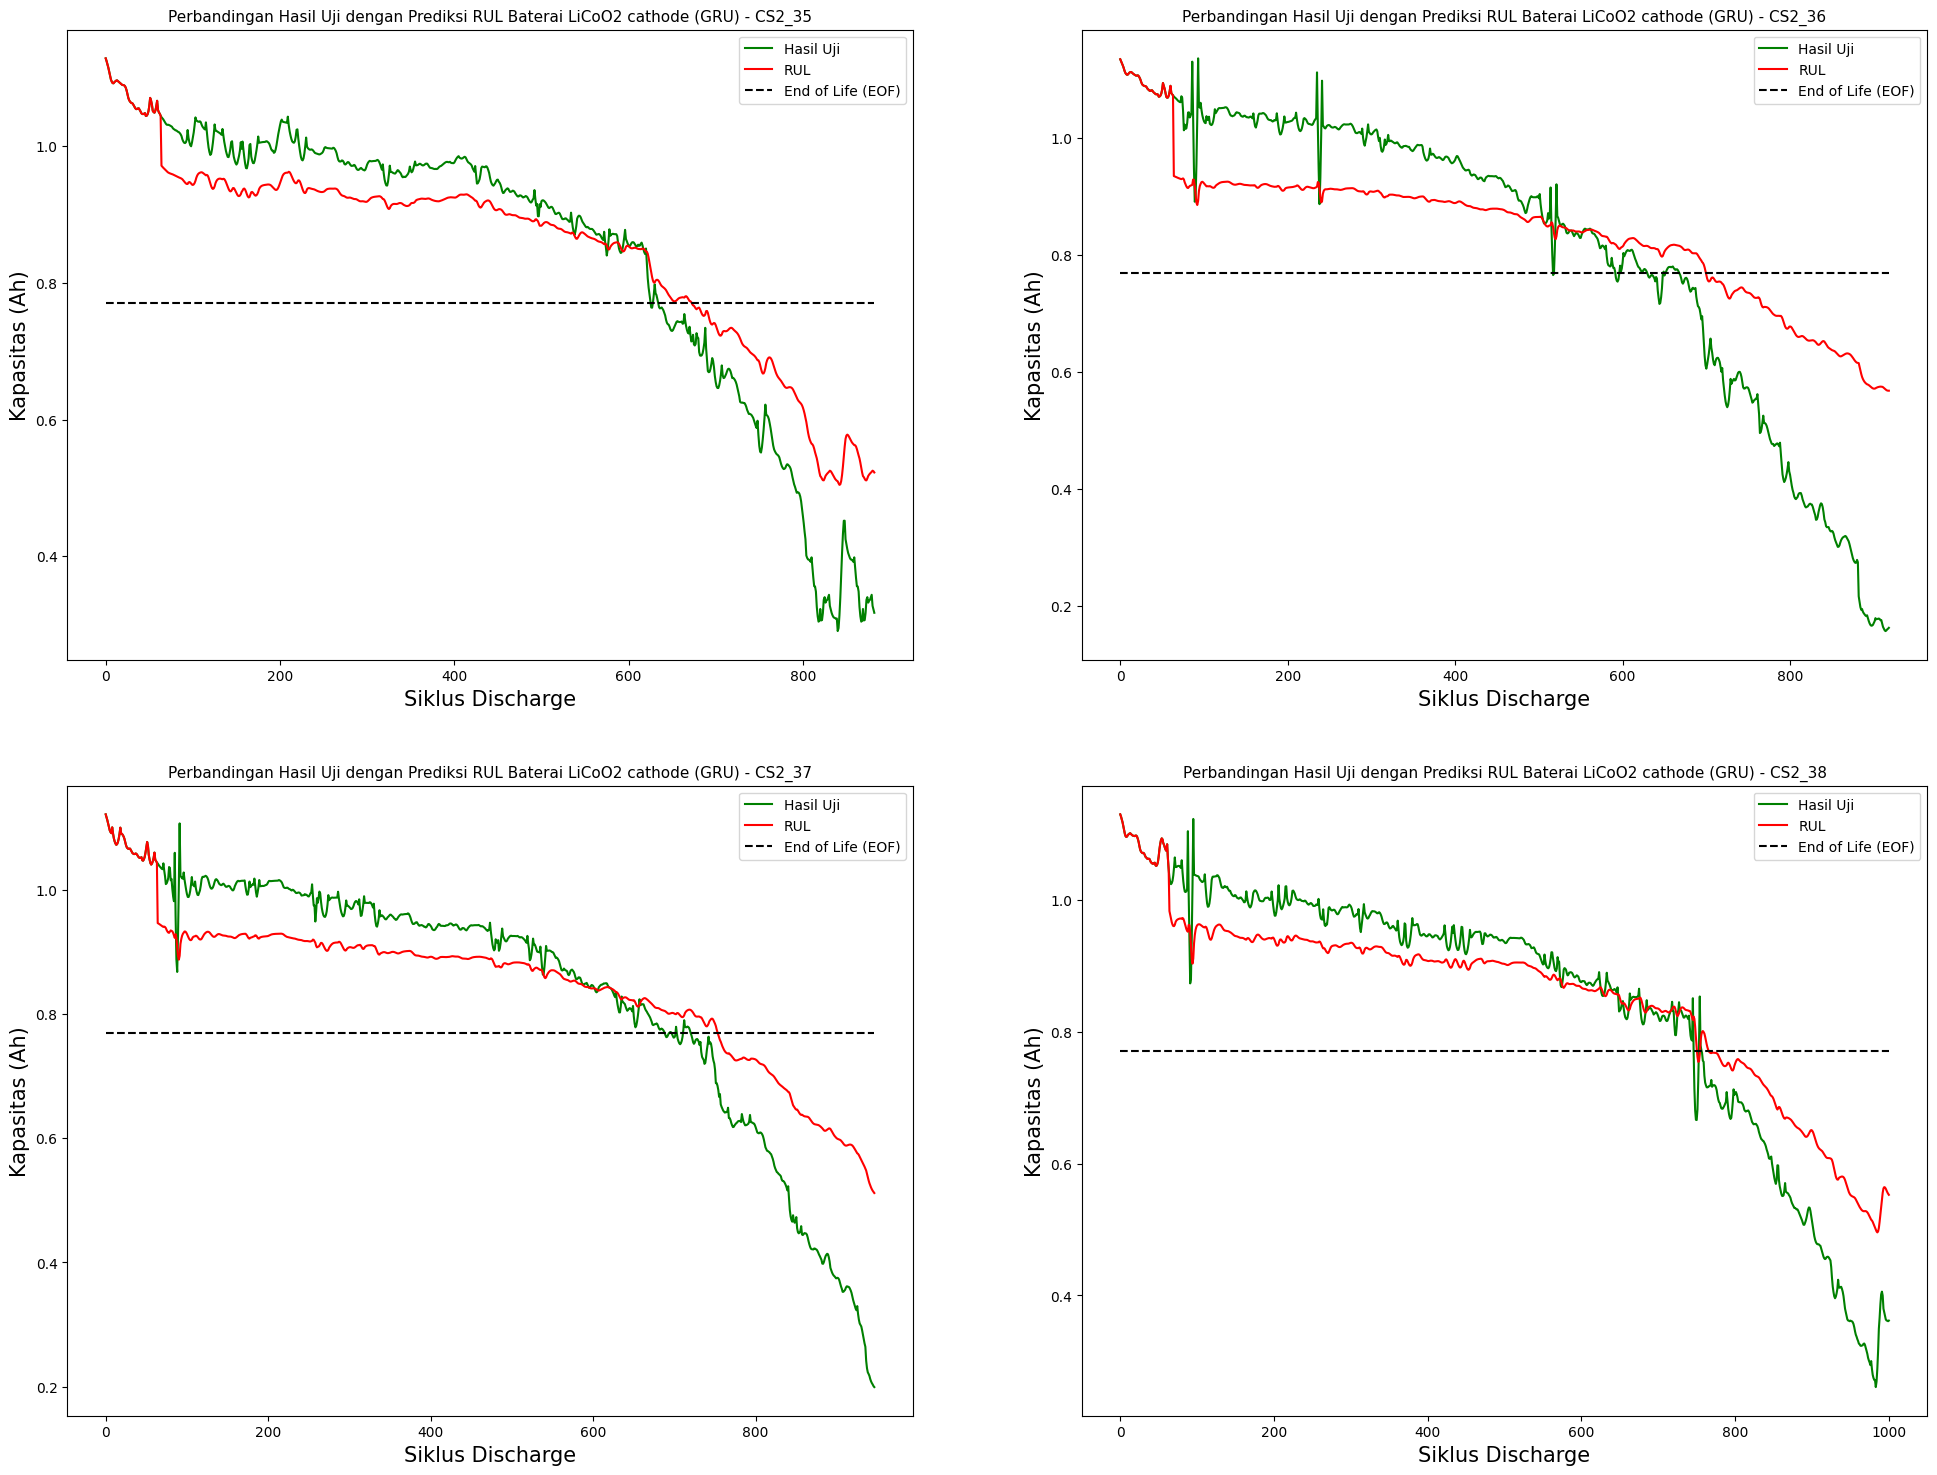

In [22]:
# Single Training Run: GRU
seed = 2
feature_size = 64
epochs = 100
lr = 0.001
hidden_dim = 64
num_layers = 1
weight_decay = 0.0
Rated_Capacity = 1.1
mode = 'GRU'
metric = 'rmse'
device = 'cpu'

print('seed:', seed)
score_list, prediction_list = train_model(lr=lr, feature_size=feature_size, hidden_dim=hidden_dim,
                                          num_layers=num_layers, weight_decay=weight_decay,
                                          mode=mode, epochs=epochs, seed=seed, device=device,
                                          metric=metric)

print("[BT1]", "    ", f"RE : {score_list[0][0]:3f}", ", ", f"MAE : {score_list[0][1]:3f}", ", ", f"RMSE : {score_list[0][2]:3f}", ", ", f"R2 : {score_list[0][3]:3f}")
print("[BT2]", "    ", f"RE : {score_list[1][0]:3f}", ", ", f"MAE : {score_list[1][1]:3f}", ", ", f"RMSE : {score_list[1][2]:3f}", ", ", f"R2 : {score_list[1][3]:3f}")
print("[BT3]", "    ", f"RE : {score_list[2][0]:3f}", ", ", f"MAE : {score_list[2][1]:3f}", ", ", f"RMSE : {score_list[2][2]:3f}", ", ", f"R2 : {score_list[2][3]:3f}")
print("[BT4]", "    ", f"RE : {score_list[3][0]:3f}", ", ", f"MAE : {score_list[3][1]:3f}", ", ", f"RMSE : {score_list[3][2]:3f}", ", ", f"R2 : {score_list[3][3]:3f}")

fig, ax = plt.subplots(2, 2, figsize=(24, 18))

for i in range(2):
    for j in range(2):
        t = 2 * i + j
        battery_name = Battery_list[t]
        test_data = Battery[battery_name]['capacity']
        predict_data = prediction_list[t]
        score_data = score_list[t]
        x = list(range(len(test_data)))
        threshold = [Rated_Capacity * 0.7] * len(test_data)

        ax[i][j].plot(x, test_data, 'g', label='Hasil Uji')
        ax[i][j].plot(x, predict_data, 'r', label='RUL')
        ax[i][j].plot(x, threshold, 'black', ls='--', label='End of Life (EOF)')
        ax[i][j].legend()
        ax[i][j].set_xlabel('Siklus Discharge', fontsize=15)
        ax[i][j].set_ylabel('Kapasitas (Ah)', fontsize=15)
        ax[i][j].set_title(f'Perbandingan Hasil Uji dengan Prediksi RUL Baterai LiCoO2 cathode (GRU) - {battery_name}', fontsize=11)

plt.savefig("./Gambar/SOH & RUL (GRU).png")
plt.show()
